# Compress the saved boundary with nvCOMP

Boundary saving keeps a strip of the wavefield at every time step and rebuilds
the wavefield from it in the backward pass. `BoundarySaving(compress="bitcomp")`
runs every chunk of that strip through nvCOMP's lossless Bitcomp coder on the
copy stream and keeps the packed bytes instead: in a device arena
(`storage="gpu"`), a pinned host arena (`"cpu"`) or one sparse file (`"disk"`).
Lossless means the gradient is **bit-identical** to the same `storage_dtype`
without it; what changes is bytes.

Needs `impl="c"` on a CUDA device and the nvCOMP 6 library:
`pip install nvidia-nvcomp-cu12`, or `SWEEP_NVCOMP_LIB=/path/to/libnvcomp.so.6`.
A missing library raises, nothing falls back.

## 1. Setup — Marmousi (25 m), one shot

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.equations import Acoustic
from sweep.propagator.torch import PropTorch
from sweep.propagator.options import BoundarySaving
from sweep.signal import ricker
from sweep.datasets import load_marmousi, MARMOUSI_DH
from sweep.backend.c import nvcomp

nvcomp.find_library()          # raises ImportError with the pip line if nvCOMP is missing
device = torch.device('cuda')

dh, dt, nt = MARMOUSI_DH * 2, 0.002, 2000
vp_np = load_marmousi('true')[::2, ::2].copy()
nz, nx = vp_np.shape
src = np.array([[nx // 2, 2]], np.int32)                       # (x, z)
rec = np.array([[[x, 4] for x in range(4, nx - 4, 4)]], np.int32)
t = np.arange(nt, dtype=np.float32) * dt
wav = torch.tensor(ricker(t - 0.2, f=5.0), device=device)


def gradient(memory):
    prop = PropTorch(Acoustic(spatial_order=4, device=device, backend='torch'),
                     shape=(nz, nx), device=device, dh=dh, dt=dt, nt=nt, abcn=20,
                     free_surface=True, pml_type='cpmlr', source_type=['h1'],
                     receiver_type=['h1'], backend='torch', impl='c', memory=memory)
    vp = torch.tensor(vp_np, device=device, requires_grad=True)
    d = prop(wav, src, rec, models=[vp])
    (0.5 * (d ** 2).sum()).backward()
    return vp.grad.detach(), prop

## 2. The same gradient, fewer bytes

Two gradients from the same int8 ring on device storage, one with
`compress="bitcomp"`. With compression the device store is a ring of
`transfer_interval` steps whose chunks are compressed as they fill (default
16 steps, `ring_buffers=2`); `compress_budget` sizes the arena the packed
chunks land in, as a fraction of the uncompressed ring (section 4).

bit-identical: True   ratio (uncompressed / packed): 2.43


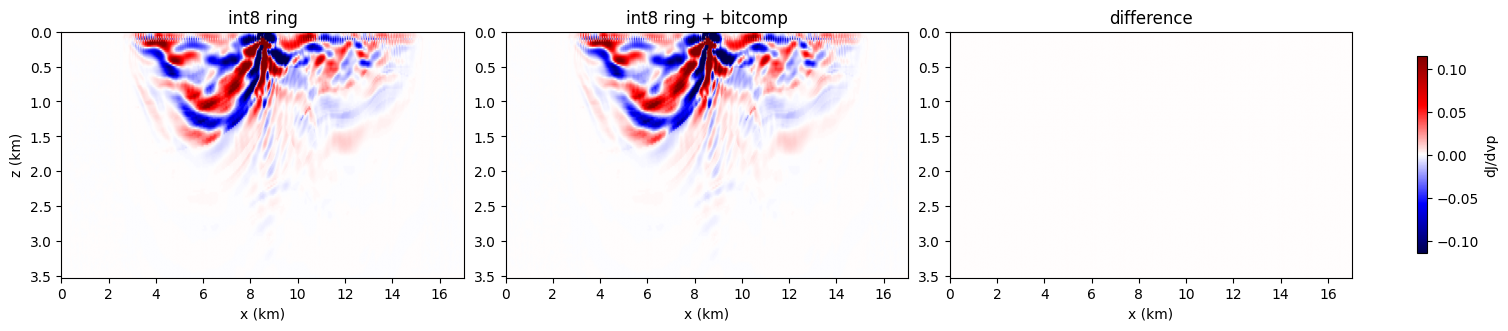

In [2]:
g_off, _ = gradient(BoundarySaving(storage='gpu', storage_dtype='int8'))
g_on, prop = gradient(BoundarySaving(storage='gpu', storage_dtype='int8',
                                     compress='bitcomp', compress_budget=0.6))
print('bit-identical:', torch.equal(g_off, g_on),
      '  ratio (uncompressed / packed): %.2f' % prop.last_boundary_compress_ratio)

ext = [0, nx * dh / 1e3, nz * dh / 1e3, 0]
v = torch.quantile(g_off.abs().flatten(), 0.99).item()   # clip the near-source cells
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2), constrained_layout=True)
for a, g, t in zip(ax, (g_off, g_on, g_on - g_off), ('int8 ring', 'int8 ring + bitcomp', 'difference')):
    im = a.imshow(g.cpu(), cmap='seismic', vmin=-v, vmax=v, extent=ext, aspect='auto')
    a.set_title(t); a.set_xlabel('x (km)')
ax[0].set_ylabel('z (km)')
fig.colorbar(im, ax=ax, shrink=0.8, label='dJ/dvp')
plt.show()

## 3. How much each storage dtype packs

The coder is told the element width, so an fp32 ring packs by its exponent
structure and a uint8 ring by its byte statistics. `boundary_compress_report()`
gives the packed and uncompressed bytes per face after a forward.

fp32: ring   37.7 MB -> packed   19.0 MB  (ratio 1.98;  top 1.8, bottom 1.8, left 3.3, right 3.2)


bf16: ring   18.8 MB -> packed    8.2 MB  (ratio 2.29;  top 2.1, bottom 2.1, left 4.0, right 3.8)


fp16: ring   18.8 MB -> packed    7.8 MB  (ratio 2.43;  top 2.4, bottom 2.1, left 4.5, right 4.2)


int8: ring    9.4 MB -> packed    3.9 MB  (ratio 2.43;  top 2.4, bottom 2.1, left 5.1, right 4.5)


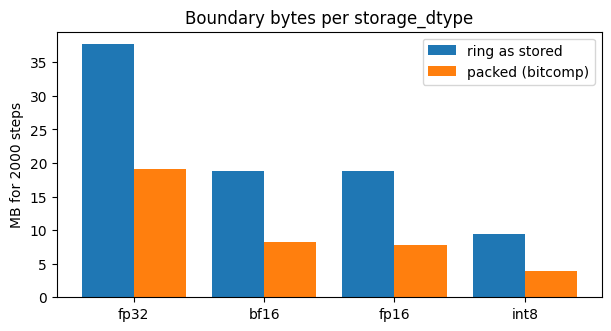

In [3]:
dtypes = ('fp32', 'bf16', 'fp16', 'int8')
raw, packed = [], []
for dtype in dtypes:
    _, prop = gradient(BoundarySaving(storage='gpu', storage_dtype=dtype,
                                      compress='bitcomp', compress_budget=1.0))
    rep = prop.boundary_compress_report()
    raw.append(rep['raw'] / 2**20); packed.append(rep['packed'] / 2**20)
    print(f"{dtype}: ring {raw[-1]:6.1f} MB -> packed {packed[-1]:6.1f} MB  (ratio {rep['ratio']:.2f};  "
          + ', '.join(f"{f} {r / p:.1f}" for f, (r, p) in rep['faces'].items()) + ')')

x = np.arange(len(dtypes))
fig, ax = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
ax.bar(x - 0.2, raw, 0.4, label='ring as stored')
ax.bar(x + 0.2, packed, 0.4, label='packed (bitcomp)')
ax.set_xticks(x, dtypes); ax.set_ylabel('MB for %d steps' % nt); ax.legend()
ax.set_title('Boundary bytes per storage_dtype')
plt.show()

## 4. The budget

The packed size is only known as the forward runs, so the arena is allocated
up front at `compress_budget` times the uncompressed ring. The bytes a run
saves are `1 - compress_budget`, not the ratio it reaches; a budget below the
ratio raises, naming the ratio and the budget to set. The disk file is sparse
and takes no budget.

On a ring this small (9 MB) the fixed workspace is visible: the device ring of
`transfer_interval x ring_buffers` steps, the bound and pack slots and the index
add a few MB, so `compress_budget=1.0` costs more than no compression and the
saving only appears once the budget is well below one. The saving is
`(1 - compress_budget) x ring - workspace`, and the workspace does not grow with
the record, which is why the option belongs on large rings (section 5).

budget 0.3 -> boundary compression: the packed ring (2980920 B after chunk 108 of 125) exceeds the arena of 2966400 B = compress_budget x the uncompressed ring ...


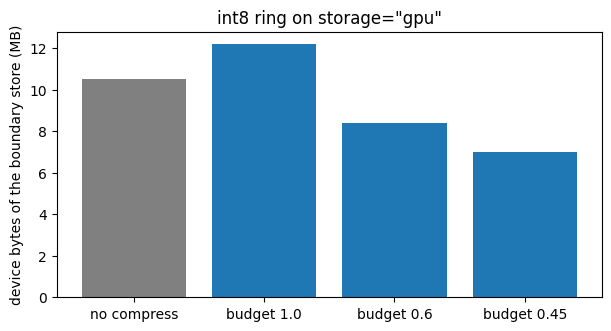

In [4]:
def device_store_mb(prop):
    seen, total = set(), 0
    for group in (prop.boundary_cpu, prop.boundary_gpu, prop.boundary_gpu_full,
                  prop.boundary_staging, prop.boundary_compress, (prop.last_two,)):
        for t in group:
            if isinstance(t, torch.Tensor) and t.is_cuda:
                key = t.untyped_storage().data_ptr()
                if key not in seen:
                    seen.add(key); total += t.untyped_storage().nbytes()
    return total / 2**20

labels, mb = ['no compress'], []
_, prop = gradient(BoundarySaving(storage='gpu', storage_dtype='int8'))
mb.append(device_store_mb(prop))
for budget in (1.0, 0.6, 0.45):
    _, prop = gradient(BoundarySaving(storage='gpu', storage_dtype='int8',
                                      compress='bitcomp', compress_budget=budget))
    labels.append(f'budget {budget}'); mb.append(device_store_mb(prop))
try:
    gradient(BoundarySaving(storage='gpu', storage_dtype='int8', compress='bitcomp', compress_budget=0.3))
except RuntimeError as e:
    print('budget 0.3 ->', str(e).split('. ')[0], '...')

fig, ax = plt.subplots(figsize=(6, 3.2), constrained_layout=True)
ax.bar(labels, mb, color=['0.5', 'C0', 'C0', 'C0'])
ax.set_ylabel('device bytes of the boundary store (MB)')
ax.set_title('int8 ring on storage="gpu"')
plt.show()

## 5. When it pays

The chunk kernels run on the copy stream and hide behind the next chunk's
compute only when there is compute to hide behind. Measured per-step cost of
`compress` (forward with saving plus backward, int8, RTX 6000 Ada):

| step time | problem | extra per step |
| --- | --- | --- |
| 0.06–0.14 ms | 2-D grids up to 280×1360, a 48×64×64 box | 2–8 % |
| 0.5 ms | 100×160×160 | ~1 % |
| ≥ 1.8 ms | 160×256×256 and larger | ≤ 1 % |

So it belongs where the ring is what limits the problem size: large 3-D
problems, where `storage_dtype="int8"` plus `compress` keeps 7–14 % of an fp32
ring. `storage="cpu"` and `"disk"` take the same option (`"disk"` needs
`disk_async_read=True`); `ModelParallel` inherits it per tile. Details:
[Boundary ring compression](../user-guide/propagators.md#bs-compress) in the
propagators guide.

**Download this notebook** &mdash; [`35_boundary_ring_compression.ipynb`](35_boundary_ring_compression.ipynb) &middot; or [view on GitHub](https://github.com/DeepWave-KAUST/sweep/blob/dev/examples/notebooks/35_boundary_ring_compression.ipynb)